# Student Stress Level Prediction
### MLOP Summative Assignment
**Author:** Nazira Umucyo, BSc Software Engineering (Machine Learning), African Leadership University

## Problem
Stress affects students' health, sleep, relationships, and academic performance, yet it often goes unnoticed until it becomes serious. This project builds a model that predicts a student's stress level (**low, medium, or high**) from psychological, physiological, environmental, academic, and social factors.

The goal is an **early screening tool** that can help students and schools spot who may need support. It is **not a diagnostic tool** and does not replace a mental health professional.

## Dataset
- **Source:** [Student Stress Factors: A Comprehensive Analysis](https://www.kaggle.com/datasets/rxnach/student-stress-factors-a-comprehensive-analysis) (Kaggle)
- **Size:** 1,100 students, 20 features, 1 target
- **Target:** `stress_level` (0 = low, 1 = medium, 2 = high)
- **Feature groups:**
  - *Psychological:* anxiety level, self-esteem, mental health history, depression
  - *Physiological:* headache, blood pressure, sleep quality, breathing problems
  - *Environmental:* noise level, living conditions, safety, basic needs
  - *Academic:* academic performance, study load, teacher-student relationship, future career concerns
  - *Social:* social support, peer pressure, extracurricular activities, bullying

## 1. Setup and Data Loading
We import the libraries and fix the random seed (42) for Python, NumPy, and TensorFlow so that results are reproducible. We then load the dataset and run basic quality checks: its shape, missing values, duplicate rows, and the balance of the three stress classes.

In [1]:
# Step 1: Imports, reproducibility, and loading the data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import random, os

# Fix random seeds so results are the same every run
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Upload the CSV from your computer
from google.colab import files
uploaded = files.upload()   # choose StressLevelDataset.csv

df = pd.read_csv("StressLevelDataset.csv")

print("Shape:", df.shape)
print("\nMissing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nClass balance (0 = low, 1 = medium, 2 = high):")
print(df["stress_level"].value_counts().sort_index())
df.head()

Saving StressLevelDataset.csv to StressLevelDataset.csv
Shape: (1100, 21)

Missing values: 0
Duplicate rows: 0

Class balance (0 = low, 1 = medium, 2 = high):
stress_level
0    373
1    358
2    369
Name: count, dtype: int64


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,0,11,2,1,2,4,2,3,...,2,3,2,3,3,2,3,3,2,1
1,15,8,1,15,5,3,1,4,3,1,...,2,1,4,1,5,1,4,5,5,2
2,12,18,1,14,2,1,2,2,2,2,...,2,2,3,3,2,2,3,2,2,1
3,16,12,1,15,4,3,1,3,4,2,...,2,2,4,1,4,1,4,4,5,2
4,16,28,0,7,2,3,5,1,3,2,...,3,4,3,1,2,1,5,0,5,1


**Observations:** The dataset has 1,100 rows and 21 columns, all numeric. There are no missing values and no duplicate rows, so no imputation or deduplication is needed. The three classes are almost perfectly balanced (373 low, 358 medium, 369 high), so we do not need class weights or resampling, and accuracy is a meaningful metric alongside precision, recall, and F1.

## 2. Exploratory Data Analysis
We explore the data to understand how each factor relates to stress before building the model. These charts also become the data insights shown in the deployed app.

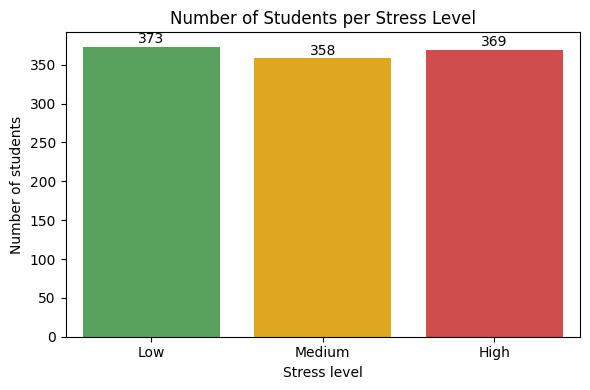

In [2]:
# 2.1 Class distribution
os.makedirs("figures", exist_ok=True)
labels = {0: "Low", 1: "Medium", 2: "High"}

plt.figure(figsize=(6, 4))
counts = df["stress_level"].map(labels).value_counts().reindex(["Low", "Medium", "High"])
sns.barplot(x=counts.index, y=counts.values, hue=counts.index,
            palette=["#4caf50", "#ffb300", "#e53935"], legend=False)
plt.title("Number of Students per Stress Level")
plt.xlabel("Stress level"); plt.ylabel("Number of students")
for i, v in enumerate(counts.values):
    plt.text(i, v + 5, str(v), ha="center")
plt.tight_layout()
plt.savefig("figures/class_distribution.png", dpi=150)
plt.show()

**Observation:** The three stress levels are almost equally represented (373 low, 358 medium, 369 high), so the model will not be biased toward one class.

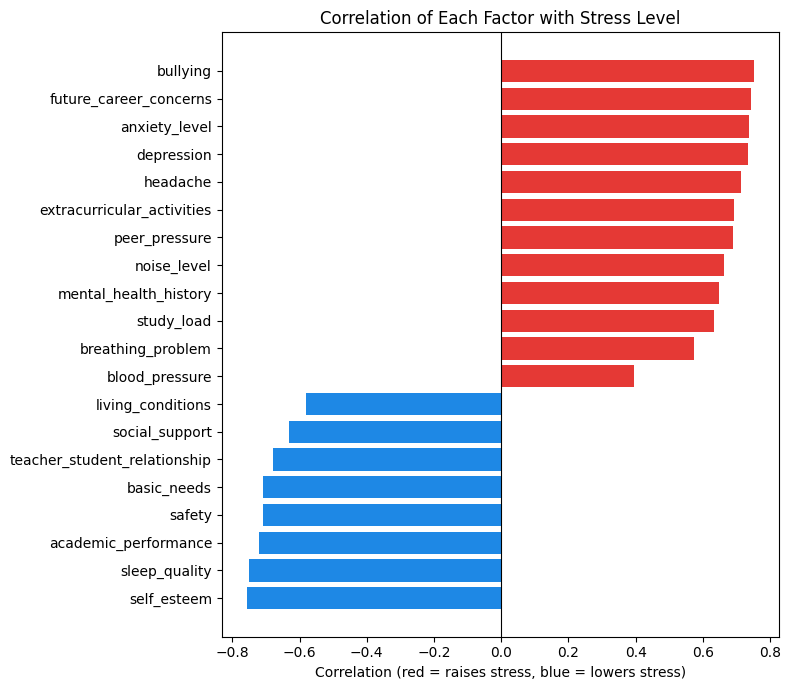

In [3]:
# 2.2 Correlation of each feature with stress level
corr_target = df.corr()["stress_level"].drop("stress_level").sort_values()

plt.figure(figsize=(8, 7))
colors = ["#1e88e5" if v < 0 else "#e53935" for v in corr_target.values]
plt.barh(corr_target.index, corr_target.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation of Each Factor with Stress Level")
plt.xlabel("Correlation (red = raises stress, blue = lowers stress)")
plt.tight_layout()
plt.savefig("figures/feature_correlation.png", dpi=150)
plt.show()

**Observation:** Every factor has a clear link with stress. The strongest stress-raising factors are **bullying (0.75)**, **future career concerns (0.74)**, **anxiety (0.74)**, and **depression (0.73)**. The strongest protective factors are **self-esteem (−0.76)**, **sleep quality (−0.75)**, and **academic performance (−0.72)**. Blood pressure has the weakest link (0.39). Interestingly, extracurricular activities are linked to higher stress (0.69), possibly because they add to students’ workload rather than acting as a release.

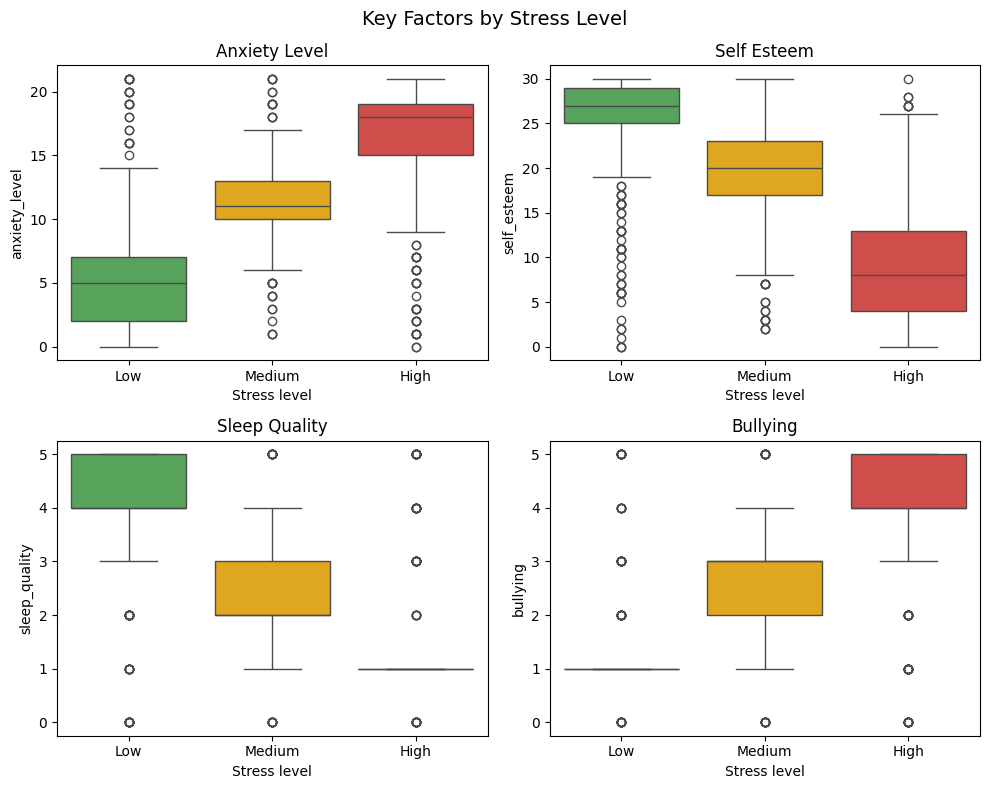

In [4]:
# 2.3 Box plots of key factors by stress level
key_features = ["anxiety_level", "self_esteem", "sleep_quality", "bullying"]
plot_df = df.copy()
plot_df["stress"] = plot_df["stress_level"].map(labels)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, feat in zip(axes.flat, key_features):
    sns.boxplot(data=plot_df, x="stress", y=feat, hue="stress",
                order=["Low", "Medium", "High"],
                palette={"Low": "#4caf50", "Medium": "#ffb300", "High": "#e53935"},
                legend=False, ax=ax)
    ax.set_title(feat.replace("_", " ").title())
    ax.set_xlabel("Stress level")
plt.suptitle("Key Factors by Stress Level", fontsize=14)
plt.tight_layout()
plt.savefig("figures/key_factors_boxplot.png", dpi=150)
plt.show()

**Observation:** The groups separate clearly. Average anxiety rises from **5.4** (low stress) to **16.4** (high stress), and bullying from **1.3** to **4.1**. Self-esteem falls from **25.3** to **8.8**, and sleep quality from **4.1** to **1.3**. Students with high stress tend to sleep poorly, have low self-esteem, and experience more bullying.

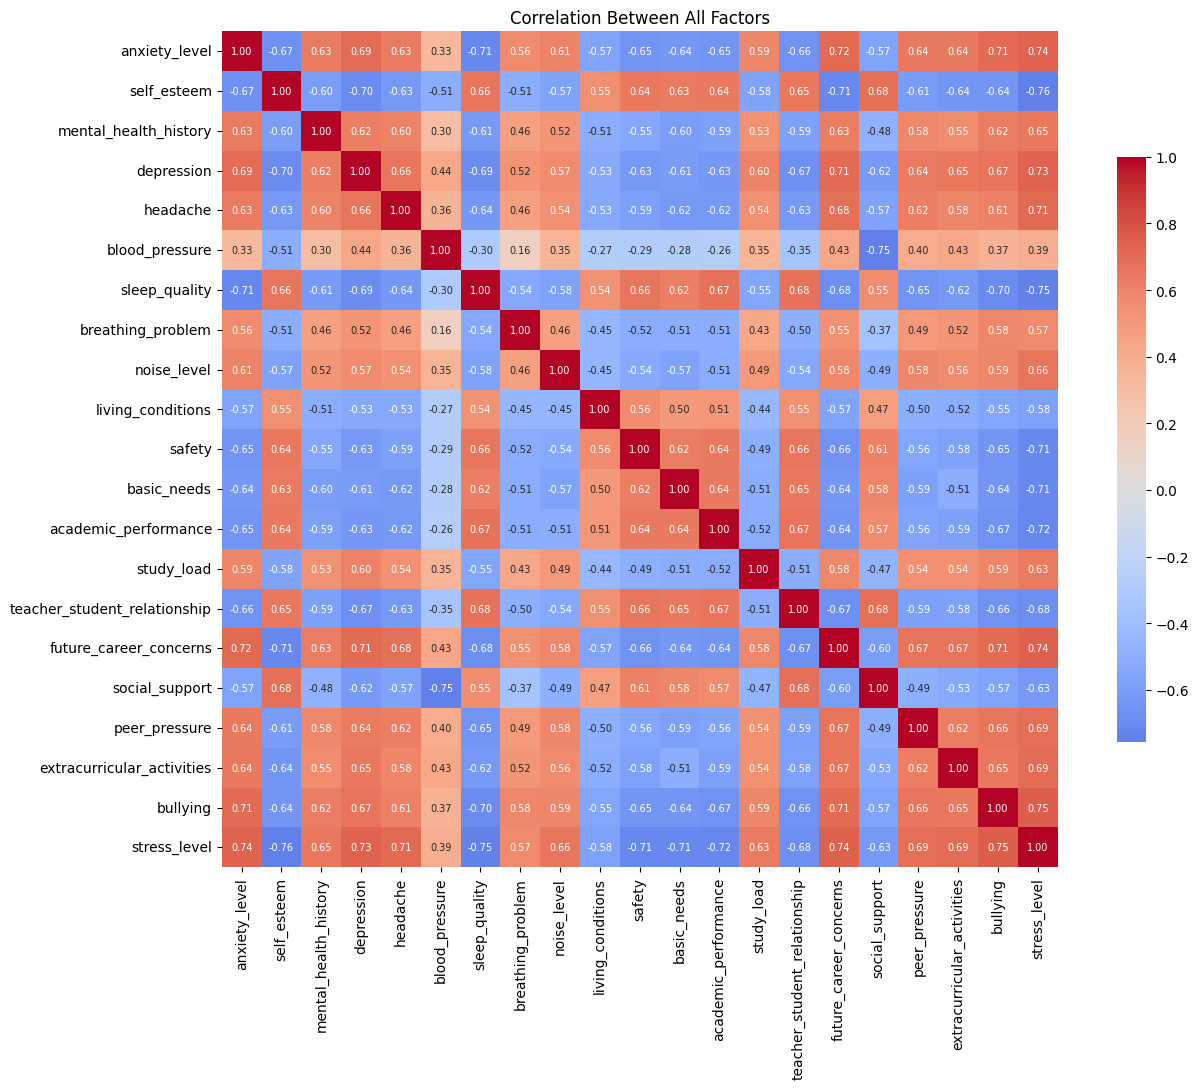

In [5]:
# 2.4 Correlation heatmap between all features
plt.figure(figsize=(14, 11))
sns.heatmap(df.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, square=True, cbar_kws={"shrink": 0.7})
plt.title("Correlation Between All Factors")
plt.tight_layout()
plt.savefig("figures/correlation_heatmap.png", dpi=150)
plt.show()

**Observation:** Many factors are strongly correlated with each other (for example blood pressure and social support at 0.75, and anxiety and future career concerns at 0.72), meaning the features carry overlapping information. With only 1,100 rows, this overlap raises the risk of overfitting, which is why we will use **regularization (L2 and dropout)** and **early stopping** when training the model.

## 3. Data Preprocessing
1. **Hold-out set for retraining:** 10% of the data (110 rows) is set aside as "new data" that the model never sees during training. It is used later to demonstrate the retraining pipeline in the deployed app.
2. **Train / validation / test split:** the remaining 990 rows are split 70% / 15% / 15%, stratified by stress level so each split keeps the same class balance.
3. **Feature scaling:** features are on different ranges (e.g. self-esteem 0–30, sleep quality 0–5), so we standardise them with `StandardScaler`. The scaler is fitted on the **training set only** to prevent data leakage, then applied to the validation and test sets.
4. **Saving the scaler:** the fitted scaler is saved so that the prediction API and retraining pipeline preprocess new data in exactly the same way.

No imputation or encoding is needed: there are no missing values and all features are already numeric.

In [6]:
# Step 3: Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib, json

TARGET = "stress_level"
FEATURES = [c for c in df.columns if c != TARGET]

# 1. Set aside 10% as "new data" for the retraining demo
model_df, retrain_df = train_test_split(
    df, test_size=0.10, stratify=df[TARGET], random_state=SEED)

# 2. Train / validation / test split (70 / 15 / 15)
X = model_df[FEATURES]
y = model_df[TARGET]
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print(f"Model data: {len(model_df)} | Retrain hold-out: {len(retrain_df)}")
print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")

# 3. Scale features (fit on training data only)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

# 4. Save the scaler, feature order, and data splits
os.makedirs("models", exist_ok=True)
os.makedirs("data", exist_ok=True)
joblib.dump(scaler, "models/scaler.joblib")
with open("models/features.json", "w") as f:
    json.dump(FEATURES, f)

pd.concat([X_train, y_train], axis=1).to_csv("data/train.csv", index=False)
pd.concat([X_test, y_test], axis=1).to_csv("data/test.csv", index=False)
retrain_df.to_csv("data/retrain_sample.csv", index=False)

print("\nSaved: models/scaler.joblib, models/features.json, data/train.csv, data/test.csv, data/retrain_sample.csv")

Model data: 990 | Retrain hold-out: 110
Train: 693 | Validation: 148 | Test: 149

Saved: models/scaler.joblib, models/features.json, data/train.csv, data/test.csv, data/retrain_sample.csv


**Result:** 693 training, 148 validation, and 149 test samples, plus 110 hold-out rows saved as `retrain_sample.csv` for the retraining demo. The scaler and feature order are saved to `models/` for reuse in deployment.

## 4. Model Building and Training
We use a feed-forward neural network (Keras Sequential API) with a softmax output for the three stress classes. To find a good setup, we run **5 experiments** that vary network size, dropout, L2 regularization, and learning rate:

- **A (baseline):** a vanilla network with no regularization and no early stopping, trained for 100 epochs. This shows what happens without optimization.
- **B–E (optimized):** combinations of the following techniques:
  - **Dropout:** randomly switches off neurons during training so the network cannot rely on any single feature.
  - **L2 regularization:** penalizes large weights, which keeps the model simpler.
  - **Adam optimizer:** adapts the learning rate for each weight.
  - **Early stopping:** stops training when validation loss stops improving (patience = 15) and restores the best weights.

The best model is chosen by **lowest validation loss**. The test set is not used until the final evaluation.

In [7]:
# 4.1 Build the model and run experiments
from tensorflow import keras
from tensorflow.keras import layers, regularizers

def build_model(units=(64, 32), dropout=0.0, l2=0.0, lr=1e-3):
    """Build a feed-forward network for 3-class stress prediction."""
    tf.random.set_seed(SEED)
    reg = regularizers.l2(l2) if l2 > 0 else None
    model = keras.Sequential([keras.Input(shape=(X_train_s.shape[1],))])
    for u in units:
        model.add(layers.Dense(u, activation="relu", kernel_regularizer=reg))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(3, activation="softmax"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

experiments = [
    {"name": "A_baseline",   "units": (64, 32),  "dropout": 0.0, "l2": 0.0,  "lr": 1e-3, "early_stop": False},
    {"name": "B_dropout_l2", "units": (64, 32),  "dropout": 0.3, "l2": 1e-3, "lr": 1e-3, "early_stop": True},
    {"name": "C_smaller",    "units": (32, 16),  "dropout": 0.2, "l2": 1e-3, "lr": 1e-3, "early_stop": True},
    {"name": "D_light_l2",   "units": (32, 16),  "dropout": 0.3, "l2": 1e-4, "lr": 1e-3, "early_stop": True},
    {"name": "E_larger",     "units": (128, 64), "dropout": 0.4, "l2": 1e-3, "lr": 5e-4, "early_stop": True},
]

results, models, histories = [], {}, {}

for exp in experiments:
    model = build_model(exp["units"], exp["dropout"], exp["l2"], exp["lr"])
    callbacks = []
    if exp["early_stop"]:
        callbacks.append(keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=15, restore_best_weights=True))

    history = model.fit(X_train_s, y_train,
                        validation_data=(X_val_s, y_val),
                        epochs=200 if exp["early_stop"] else 100,
                        batch_size=32, callbacks=callbacks, verbose=0)

    train_loss, train_acc = model.evaluate(X_train_s, y_train, verbose=0)
    val_loss, val_acc = model.evaluate(X_val_s, y_val, verbose=0)
    results.append({
        "experiment": exp["name"], "layers": str(exp["units"]),
        "dropout": exp["dropout"], "l2": exp["l2"], "learning_rate": exp["lr"],
        "early_stopping": exp["early_stop"],
        "epochs_run": len(history.history["loss"]),
        "train_acc": round(train_acc, 3), "val_acc": round(val_acc, 3),
        "val_loss": round(val_loss, 3)})
    models[exp["name"]] = model
    histories[exp["name"]] = history
    print(f"Finished {exp['name']}")

results_df = pd.DataFrame(results).sort_values("val_loss")
results_df.to_csv("experiments.csv", index=False)

best_name = results_df.iloc[0]["experiment"]
best_model = models[best_name]
print(f"\nBest model (lowest validation loss): {best_name}")
results_df

Finished A_baseline
Finished B_dropout_l2
Finished C_smaller
Finished D_light_l2
Finished E_larger

Best model (lowest validation loss): D_light_l2


,experiment,layers,dropout,l2,learning_rate,early_stopping,epochs_run,train_acc,val_acc,val_loss
3,D_light_l2,"(32, 16)",0.3,0.0001,0.0010,True,41,0.926,0.845,0.270
2,C_smaller,"(32, 16)",0.2,0.0010,0.0010,True,42,0.925,0.872,0.302
1,B_dropout_l2,"(64, 32)",0.3,0.0010,0.0010,True,34,0.934,0.865,0.319
4,E_larger,"(128, 64)",0.4,0.0010,0.0005,True,43,0.942,0.878,0.367
0,A_baseline,"(64, 32)",0.0,0.0000,0.0010,False,100,1.000,0.858,0.918


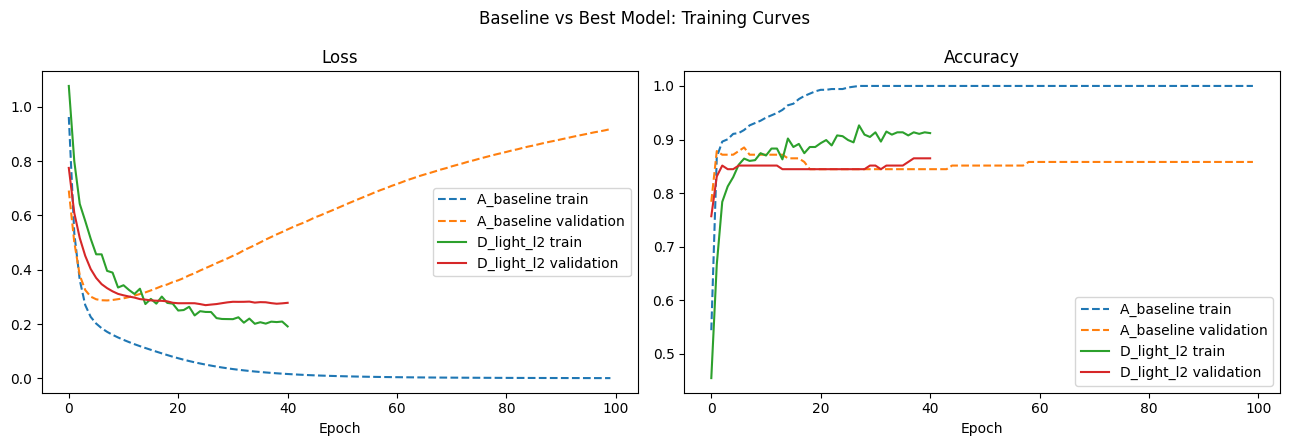

In [8]:
# 4.2 Training curves: baseline vs best model
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, style in [("A_baseline", "--"), (best_name, "-")]:
    h = histories[name].history
    axes[0].plot(h["loss"], style, label=f"{name} train")
    axes[0].plot(h["val_loss"], style, label=f"{name} validation")
    axes[1].plot(h["accuracy"], style, label=f"{name} train")
    axes[1].plot(h["val_accuracy"], style, label=f"{name} validation")

axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.suptitle("Baseline vs Best Model: Training Curves")
plt.tight_layout()
plt.savefig("figures/training_curves.png", dpi=150)
plt.show()

**Observations:**
- The **baseline (A) overfits badly**: it reaches 100% training accuracy, but its validation loss climbs to about 0.92, because it memorizes the training data.
- All optimized models (B–E) keep validation loss much lower (about 0.27–0.37). Early stopping ended training after roughly 35–45 epochs, before overfitting set in.
- **D (32-16 network, dropout 0.3, light L2)** had the lowest validation loss and is selected as the final model. A smaller network with dropout suits this small dataset (693 training rows).
- Validation accuracy is similar across models (about 85–88%), which suggests the main limit is the information in the features rather than the model design.

## 5. Model Evaluation
The final model is evaluated on the **test set** (149 students), which was not used for training or model selection. We report:
- **Accuracy:** share of all predictions that are correct.
- **Loss (cross-entropy):** how confident and well-calibrated the predicted probabilities are (lower is better).
- **Precision:** of the students predicted at a given stress level, how many truly are at that level.
- **Recall:** of the students truly at a given stress level, how many the model finds.
- **F1 score:** the balance between precision and recall.
- **ROC-AUC (one-vs-rest):** how well the model ranks students across all thresholds.

Precision, recall, and F1 are macro-averaged (each class counts equally), which is appropriate because the classes are balanced. We compare the baseline (A) with the selected model to show the effect of optimization.

In [9]:
# 5.1 Test-set metrics: baseline vs best model
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

rows = []
for name in ["A_baseline", best_name]:
    m = models[name]
    probs = m.predict(X_test_s, verbose=0)
    preds = probs.argmax(axis=1)
    loss, acc = m.evaluate(X_test_s, y_test, verbose=0)
    rows.append({
        "model": name,
        "accuracy": round(acc, 3),
        "loss": round(loss, 3),
        "precision": round(precision_score(y_test, preds, average="macro"), 3),
        "recall": round(recall_score(y_test, preds, average="macro"), 3),
        "f1_score": round(f1_score(y_test, preds, average="macro"), 3),
        "roc_auc": round(roc_auc_score(y_test, probs, multi_class="ovr"), 3)})

test_results = pd.DataFrame(rows)
test_results.to_csv("test_results.csv", index=False)
test_results

,model,accuracy,loss,precision,recall,f1_score,roc_auc
0,A_baseline,0.893,0.691,0.900,0.893,0.893,0.987
1,D_light_l2,0.886,0.266,0.896,0.886,0.887,0.990


Classification report: D_light_l2

              precision    recall  f1-score   support

         Low      0.955     0.824     0.884        51
      Medium      0.933     0.875     0.903        48
        High      0.800     0.960     0.873        50

    accuracy                          0.886       149
   macro avg      0.896     0.886     0.887       149
weighted avg      0.896     0.886     0.886       149



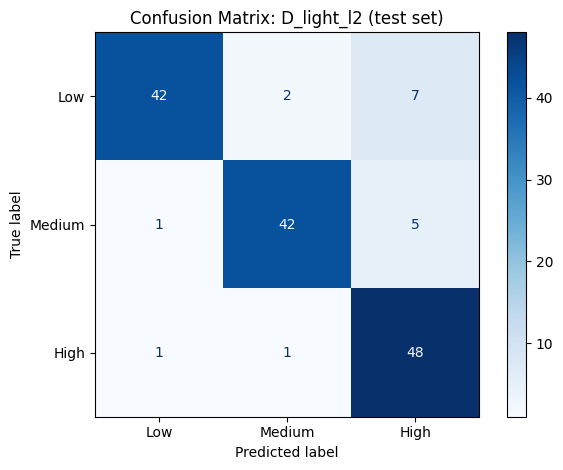

In [10]:
# 5.2 Per-class report and confusion matrix for the final model
class_names = ["Low", "Medium", "High"]
best_preds = best_model.predict(X_test_s, verbose=0).argmax(axis=1)

print(f"Classification report: {best_name}\n")
print(classification_report(y_test, best_preds, target_names=class_names, digits=3))

cm = confusion_matrix(y_test, best_preds)
disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix: {best_name} (test set)")
plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=150)
plt.show()

**Observations:**
- The final model reaches **88.6% accuracy, 0.887 F1, and 0.990 ROC-AUC** on unseen test data.
- The baseline has almost the same accuracy (89.3%), but its **loss is 2.6 times higher (0.691 vs 0.266)**. It makes extreme, overconfident predictions because it overfitted. For a screening tool, trustworthy confidence matters: the optimized model's probabilities can be shown to users meaningfully, while the baseline's cannot.
- **High stress has the best recall (0.96)**: the model finds 48 of 50 highly stressed students. This is the most important class for a screening tool, because missing a student who needs support is worse than an extra check-in.
- Most errors lean toward **over-predicting high stress** (7 low-stress and 5 medium-stress students were flagged as high). For screening, this is the safer kind of mistake.
- Only 2 of 50 high-stress students were missed (predicted as low or medium).

## 6. Saving the Model
The selected model is saved in Keras format together with the fitted scaler and feature order. We then reload the saved files and run a prediction on a raw data row to confirm the full pipeline (raw input → scaling → model → stress level) works outside the training session, exactly as the deployed API will use it.

We also record model metadata (metrics and library versions) so that retrained versions can be compared with this one, and select example rows for the prediction demo.

In [11]:
# 6.1 Save the final model and metadata
import sklearn
from datetime import datetime

best_model.save("models/stress_model.keras")

metadata = {
    "model_version": 1,
    "model_name": best_name,
    "trained_on": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "train_rows": len(X_train),
    "test_metrics": test_results[test_results["model"] == best_name].iloc[0].drop("model").to_dict(),
    "classes": {0: "Low", 1: "Medium", 2: "High"},
    "versions": {"tensorflow": tf.__version__, "scikit-learn": sklearn.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__},
}
with open("models/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=float)

# Reload everything from disk and predict one raw row, like the API will
loaded_model = keras.models.load_model("models/stress_model.keras")
loaded_scaler = joblib.load("models/scaler.joblib")
with open("models/features.json") as f:
    loaded_features = json.load(f)

sample = X_test.iloc[[0]][loaded_features]
probs = loaded_model.predict(loaded_scaler.transform(sample), verbose=0)[0]
print("True label:     ", class_names[y_test.iloc[0]])
print("Predicted label:", class_names[probs.argmax()])
print("Probabilities:  ", {c: round(float(p), 3) for c, p in zip(class_names, probs)})
print("\nVersions:", metadata["versions"])

True label:      Medium
Predicted label: Medium
Probabilities:   {'Low': 0.001, 'Medium': 0.998, 'High': 0.001}

Versions: {'tensorflow': '2.21.0', 'scikit-learn': '1.6.1', 'numpy': '2.4.6', 'pandas': '2.2.3'}


In [12]:
# 6.2 Pick confident, correct demo rows (one per class) for the video
test_probs = best_model.predict(X_test_s, verbose=0)
demo = X_test.copy()
demo["true_label"] = y_test.values
demo["predicted"] = test_probs.argmax(axis=1)
demo["confidence"] = test_probs.max(axis=1).round(3)

demo_rows = (demo[demo["true_label"] == demo["predicted"]]
             .sort_values("confidence", ascending=False)
             .groupby("true_label").head(2))
demo_rows.to_csv("data/demo_samples.csv", index=False)
print(demo_rows[["true_label", "predicted", "confidence"]])

# Zip all outputs and download them
import shutil
os.makedirs("export", exist_ok=True)
for item in ["models", "data", "figures"]:
    shutil.copytree(item, f"export/{item}", dirs_exist_ok=True)
for f in ["experiments.csv", "test_results.csv"]:
    shutil.copy(f, "export/")
shutil.make_archive("stress_project_outputs", "zip", "export")
files.download("stress_project_outputs.zip")

      true_label  predicted  confidence
428            0          0       1.000
73             0          0       1.000
569            1          1       1.000
68             1          1       1.000
1034           2          2       0.999
353            2          2       0.999


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Result:** The saved model reloads correctly and gives the same prediction from a raw input row, confirming it is ready for deployment. The following files are exported for the API and app: `stress_model.keras`, `scaler.joblib`, `features.json`, `metadata.json`, the data splits, `retrain_sample.csv`, `demo_samples.csv`, and all figures.

## 7. Conclusion
- A regularized neural network (32-16 units, dropout 0.3, L2, Adam, early stopping) predicts student stress level with **88.6% accuracy, 0.887 F1, and 0.990 ROC-AUC** on unseen test data.
- Optimization mattered more for **reliability** than for accuracy: the vanilla baseline reached similar accuracy but overfitted badly, with a test loss 2.6 times higher and overconfident predictions.
- The model finds **96% of highly stressed students**, and its errors lean toward flagging students as high stress, which is the safer direction for a screening tool.
- **Limitations:** the dataset is small (1,100 students), self-reported, and from a single survey, so results may not transfer to other student populations (for example, students in Rwanda). The model shows associations, not causes, and is not a diagnostic tool.
- **Next steps:** the saved model, scaler, and preprocessing are used in a deployed web app that supports single predictions, uploading new data, and retraining the model on it.